# 01 · Entrenamiento comparativo de YOLO-seg para tomates maduros y semimaduros

Se entrenan **tres modelos** con el mismo dataset para elegir el mejor para el sistema:

| Modelo | Arquitectura | Optimizador | Learning rate | Qué se compara |
|---|---|---|---|---|
| **MODELO 1** | yolo11s-seg | AdamW | 0.002 | Configuración base del sistema |
| **MODELO 2** | yolo11s-seg | AdamW | 0.0005 | Efecto del learning rate (4× menor) |
| **MODELO 3** | yolo11m-seg | AdamW | el mejor de 1 y 2 | Modelo más grande, con más capacidad para tomates **ocluidos** por hojas y racimos |

**Dataset:** Laboro Tomato, con una sola clase `tomate` que reúne los tomates **maduros** (`*_fully_ripened`) y **semimaduros** (`*_half_ripened`). Los verdes no se anotan, así el modelo aprende a ignorarlos.

**Por qué se incluyen los semimaduros:** en una versión anterior solo los maduros eran la clase y los semimaduros quedaban como fondo. El modelo aprendió que un tomate naranja se ignora, y bajo luz cálida de interior un tomate maduro se ve naranja: dejaba de detectarlo. Al unir ambos en `tomate`, el color ya no excluye frutos por la iluminación y además casi se duplican los ejemplos de entrenamiento. tomatOD estaba previsto como dataset complementario, pero su servidor de descarga dejó de estar disponible (HTTP 403).

**Partición sin fuga de datos:**
- El `train` de Laboro (643 imágenes) se divide en **85 % train / 15 % val**, con semilla fija.
- El `test` de Laboro (161 imágenes) queda **reservado**.
- El mejor learning rate se elige con **val**. La comparación final se reporta en **test**, que ningún modelo usó para tomar decisiones.

**Se puede cortar y retomar:**
- El dataset se descarga y se convierte **una sola vez** y queda guardado en Drive (`MyDrive/tomates3d/datasets/`).
- Cada modelo guarda su avance en `MyDrive/tomates3d/runs/`. Si Colab se desconecta, volvé a ejecutar todo: los modelos terminados se saltean y el que quedó a medias **continúa** desde la última época.

> En Colab: *Entorno de ejecución → Cambiar tipo → GPU T4*. Tiempo aproximado: ~50 min por cada modelo `s` y ~1,5 h el `m`.

In [2]:
# ---------------------------------------------------------------- configuración
import json
import math
import os
import random
import shutil
import subprocess
import sys
import time
import urllib.request
import zipfile
from collections import Counter, defaultdict
from pathlib import Path

try:
    import google.colab  # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    from google.colab import drive
    if not os.path.isdir("/content/drive/MyDrive"):
        drive.mount("/content/drive")
    BASE_DIR = "/content/drive/MyDrive/tomates3d"   # persistente (Drive)
    WORK_DIR = "/content/data"                       # disco local de Colab: rápido, se borra al cerrar
    import importlib.util
    if importlib.util.find_spec("ultralytics") is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
else:
    BASE_DIR = os.environ.get("TOMATES_DIR", str(Path.cwd().parent))
    WORK_DIR = os.environ.get("TOMATES_WORK", os.path.join(BASE_DIR, "data_local"))

DATASETS_DIR = os.path.join(BASE_DIR, "datasets")   # zips guardados en Drive
RUNS_DIR = os.path.join(BASE_DIR, "runs", "clase_tomate")  # entrenamientos y métricas (versión maduro + semimaduro)
WEIGHTS_DIR = os.path.join(BASE_DIR, "weights")     # modelo elegido para los notebooks 02 y 03
DATA_DIR = os.path.join(WORK_DIR, "tomate_yolo")

LABORO_URL = "http://assets.laboro.ai.s3.amazonaws.com/laborotomato/laboro_tomato.zip"
LABORO_ZIP = os.path.join(DATASETS_DIR, "laboro_tomato.zip")
DATASET_ZIP = os.path.join(DATASETS_DIR, "tomate_yolo.zip")  # maduro + semimaduro

SEED = 0
VAL_FRAC = 0.15
EPOCHS = 100
IMGSZ = 640
BATCH = 16

for d in (DATASETS_DIR, RUNS_DIR, WEIGHTS_DIR, WORK_DIR):
    os.makedirs(d, exist_ok=True)
print("Proyecto (persistente):", BASE_DIR)
print("Datos de trabajo (local):", WORK_DIR)

Mounted at /content/drive
Proyecto (persistente): /content/drive/MyDrive/tomates3d
Datos de trabajo (local): /content/data


## 1. Conversión de Laboro Tomato a YOLO-seg (maduros y semimaduros)
- Se conservan las categorías **`*_fully_ripened`** (maduros) y **`*_half_ripened`** (semimaduros), de tomates grandes (`b_`) y cherry (`l_`), y se asignan a la clase `0: tomate`. Los verdes (`*_green`) se descartan.
- Se usa el polígono de mayor área de cada máscara. Si una anotación no trae máscara, se aproxima con una elipse inscrita en su caja.
- Las imágenes sin tomates de la clase se conservan como **ejemplos negativos** (archivo de etiquetas vacío).
- Las imágenes se reducen a 1280 px de lado mayor (las originales son de 3024×4032).
- El `.json` con `test` en el nombre va a **test**. El de `train` se divide en train/val con la semilla `SEED`.

In [4]:
import cv2

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}


def es_tomate(nombre_categoria: str) -> bool:
    """Maduro (fully_ripened) o semimaduro (half_ripened); los verdes quedan afuera."""
    n = nombre_categoria.lower()
    return "fully" in n or "half" in n or "semi" in n


def poligono_elipse(x, y, w, h, n=32):
    cx, cy, a, b = x + w / 2, y + h / 2, w / 2, h / 2
    pts = []
    for i in range(n):
        t = 2 * math.pi * i / n
        pts += [cx + a * math.cos(t), cy + b * math.sin(t)]
    return pts


def mejor_poligono(ann) -> list[float] | None:
    seg = ann.get("segmentation")
    if isinstance(seg, list) and seg:
        polys = [p for p in seg if isinstance(p, list) and len(p) >= 6]
        if polys:
            def area(p):
                xs, ys = p[0::2], p[1::2]
                return abs(sum(xs[i] * ys[i - 1] - xs[i - 1] * ys[i] for i in range(len(xs)))) / 2
            return max(polys, key=area)  # YOLO-seg admite un polígono por instancia
    return None


def convertir_dataset(root: str, out: str, prefijo: str, max_lado: int = 1280,
                      val_frac: float = VAL_FRAC, seed: int = SEED) -> Counter:
    stats = Counter()
    root, out = Path(root), Path(out)
    indice = {p.name: p for p in root.rglob("*") if p.suffix.lower() in IMG_EXT}
    for jp in sorted(root.rglob("*.json")):
        try:
            coco = json.loads(jp.read_text(encoding="utf-8"))
        except (json.JSONDecodeError, UnicodeDecodeError):
            continue
        if not all(k in coco for k in ("images", "annotations", "categories")):
            continue
        es_test = "test" in jp.name.lower()
        cats = {c["id"]: c["name"] for c in coco["categories"]}
        anns = defaultdict(list)
        for a in coco["annotations"]:
            anns[a["image_id"]].append(a)
        # Partición determinista train/val: misma semilla = mismas imágenes en val en cada corrida.
        nombres = sorted(Path(im["file_name"]).name for im in coco["images"])
        random.Random(seed).shuffle(nombres)
        en_val = set() if es_test else set(nombres[:round(len(nombres) * val_frac)])
        print(f"[{prefijo}] {jp.name}: {len(coco['images'])} imágenes "
              f"({'test' if es_test else f'train + {len(en_val)} a val'}) | "
              f"categorías incluidas: {sorted(n for n in cats.values() if es_tomate(n))}")
        for im in coco["images"]:
            nombre_img = Path(im["file_name"]).name
            split = "test" if es_test else ("val" if nombre_img in en_val else "train")
            src = indice.get(nombre_img)
            if src is None:
                stats["imagenes_faltantes"] += 1
                continue
            img = cv2.imread(str(src))
            if img is None:
                stats["imagenes_ilegibles"] += 1
                continue
            H, W = img.shape[:2]
            lineas = []
            for a in anns.get(im["id"], []):
                if not es_tomate(cats[a["category_id"]]):
                    stats["descartados_verdes"] += 1
                    continue
                poly = mejor_poligono(a)
                if poly is None:
                    poly = poligono_elipse(*a["bbox"])
                    stats["tomates_desde_caja"] += 1
                else:
                    stats["tomates_desde_mascara"] += 1
                norm = []
                for i in range(0, len(poly), 2):
                    norm += [min(max(poly[i] / W, 0), 1), min(max(poly[i + 1] / H, 0), 1)]
                lineas.append("0 " + " ".join(f"{v:.6f}" for v in norm))
            stats[f"tomates_{split}"] += len(lineas)
            stats[f"imagenes_{split}"] += 1
            if not lineas:
                stats[f"imagenes_negativas_{split}"] += 1
            escala = max_lado / max(H, W)
            if escala < 1:
                img = cv2.resize(img, None, fx=escala, fy=escala, interpolation=cv2.INTER_AREA)
            nombre = f"{prefijo}_{src.stem}"
            (out / "images" / split).mkdir(parents=True, exist_ok=True)
            (out / "labels" / split).mkdir(parents=True, exist_ok=True)
            cv2.imwrite(str(out / "images" / split / f"{nombre}.jpg"), img, [cv2.IMWRITE_JPEG_QUALITY, 92])
            (out / "labels" / split / f"{nombre}.txt").write_text("\n".join(lineas))
    return stats


def escribir_data_yaml(out: str) -> str:
    ruta = os.path.join(out, "data.yaml")
    with open(ruta, "w") as fh:
        fh.write(f"path: {Path(out).resolve().as_posix()}\n"
                 "train: images/train\nval: images/val\ntest: images/test\n"
                 "names:\n  0: tomate\n")
    return ruta

## 2. Preparar el dataset (una sola vez, guardado en Drive)
1. Si el disco local ya tiene el dataset convertido, se usa directamente.
2. Si no, pero está `datasets/tomate_yolo.zip` en Drive, se descomprime en el disco local (unos segundos).
3. Si tampoco, se descarga `laboro_tomato.zip` **directo a Drive** (solo la primera vez), se convierte, y el resultado se guarda en Drive como `tomate_yolo.zip`.

No se entrena leyendo desde Drive porque es muy lento: se trabaja con la copia local.

In [5]:
def descargar(url: str, destino: str):
    tmp = destino + ".part"  # evita dejar un zip incompleto en Drive si se corta
    print("Descargando", url)
    urllib.request.urlretrieve(url, tmp)
    os.replace(tmp, destino)


def preparar_dataset() -> str:
    resumen_path = os.path.join(DATA_DIR, "resumen.json")
    if not os.path.isfile(resumen_path):
        if os.path.isfile(DATASET_ZIP):
            print("Restaurando dataset convertido desde", DATASET_ZIP)
            shutil.rmtree(DATA_DIR, ignore_errors=True)
            with zipfile.ZipFile(DATASET_ZIP) as z:
                z.extractall(DATA_DIR)
        else:
            if not os.path.isfile(LABORO_ZIP):
                descargar(LABORO_URL, LABORO_ZIP)
            raw = os.path.join(WORK_DIR, "raw", "laboro_tomato")
            shutil.rmtree(raw, ignore_errors=True)
            with zipfile.ZipFile(LABORO_ZIP) as z:
                z.extractall(raw)
            shutil.rmtree(DATA_DIR, ignore_errors=True)
            stats = convertir_dataset(raw, DATA_DIR, "laboro")
            with open(resumen_path, "w") as fh:
                json.dump(dict(stats), fh, indent=1)
            print("Guardando dataset convertido en Drive:", DATASET_ZIP)
            archivo = shutil.make_archive(os.path.join(WORK_DIR, "tomate_yolo"), "zip", DATA_DIR)
            shutil.copy(archivo, DATASET_ZIP + ".part")
            os.replace(DATASET_ZIP + ".part", DATASET_ZIP)
    else:
        print("Dataset local listo en", DATA_DIR)
    data_yaml = escribir_data_yaml(DATA_DIR)  # se reescribe: la ruta absoluta depende del entorno
    with open(resumen_path) as fh:
        for k, v in sorted(json.load(fh).items()):
            print(f"  {k}: {v}")
    return data_yaml


DATA_YAML = preparar_dataset()
print("\n" + open(DATA_YAML).read())

Restaurando dataset convertido desde /content/drive/MyDrive/tomates3d/datasets/tomate_yolo.zip
  descartados_verdes: 6450
  imagenes_negativas_test: 25
  imagenes_negativas_train: 75
  imagenes_negativas_val: 17
  imagenes_test: 161
  imagenes_train: 547
  imagenes_val: 96
  tomates_desde_mascara: 3327
  tomates_test: 680
  tomates_train: 2325
  tomates_val: 322

path: /content/data/tomate_yolo
train: images/train
val: images/val
test: images/test
names:
  0: tomate



## 3. Funciones de entrenamiento y evaluación

- **`entrenar()`** usa siempre AdamW, la misma semilla y los mismos aumentos de datos, para que la única diferencia entre modelos sea la que se quiere medir. `hsv_h` es bajo porque el tono es justamente lo que distingue un tomate maduro o semimaduro de uno verde.
  - Si el modelo ya terminó (existe `terminado.json`), lo saltea.
  - Si quedó a medias, continúa desde `last.pt`.
- **`evaluar()`** mide sobre `val` o `test` y guarda el resultado en `metricas_<split>.json`, para no recalcular. En detección no hay una única "accuracy"; se reportan:
  - **Precision:** de lo que detecta, cuánto es realmente un tomate (maduro o semimaduro).
  - **Recall:** de los tomates de la clase, cuántos encuentra.
  - **F1:** media armónica de las dos anteriores.
  - **mAP50:** precisión media con un solapamiento mínimo (IoU) de 0,5.
  - **mAP50-95:** promedio con IoU entre 0,5 y 0,95. Es más exigente con la forma.
  - Todo se mide para **caja** y para **máscara**. La métrica principal es **mAP50-95 de máscara**, porque la máscara es lo que se usa para medir la profundidad Z.

In [6]:
from ultralytics import YOLO

AUMENTOS = dict(degrees=10, hsv_h=0.005)


def carpeta(nombre: str) -> str:
    return os.path.join(RUNS_DIR, nombre)


def leer_results_csv(nombre: str):
    import pandas as pd
    ruta = os.path.join(carpeta(nombre), "results.csv")
    if not os.path.isfile(ruta):
        return None
    df = pd.read_csv(ruta)
    df.columns = [c.strip() for c in df.columns]
    return df


def entrenar(nombre: str, modelo_base: str, lr0: float, epochs: int = EPOCHS, imgsz: int = IMGSZ,
             batch: int = BATCH) -> dict:
    d = carpeta(nombre)
    fin = os.path.join(d, "terminado.json")
    last = os.path.join(d, "weights", "last.pt")
    if os.path.isfile(fin):
        print(f"[{nombre}] ya entrenado: se saltea.")
        with open(fin) as fh:
            return json.load(fh)
    t0 = time.time()
    if os.path.isfile(last):
        print(f"[{nombre}] continuando entrenamiento interrumpido desde {last}")
        try:
            YOLO(last).train(resume=True)
        except AssertionError as e:
            # Colab se cortó justo después de terminar: no hay nada que retomar.
            if "nothing to resume" not in str(e):
                raise
            print(f"[{nombre}] el entrenamiento ya había terminado.")
    else:
        print(f"[{nombre}] entrenando {modelo_base} con AdamW, lr0={lr0}")
        YOLO(modelo_base).train(
            data=DATA_YAML, epochs=epochs, imgsz=imgsz, batch=batch,
            optimizer="AdamW", lr0=lr0, seed=SEED, deterministic=True, patience=25,
            project=RUNS_DIR, name=nombre, exist_ok=True, plots=True, **AUMENTOS,
        )
    df = leer_results_csv(nombre)
    # results.csv trae el tiempo acumulado (incluye sesiones anteriores si se retomó).
    segundos = float(df["time"].iloc[-1]) if df is not None and "time" in df.columns else time.time() - t0
    info = {"nombre": nombre, "modelo_base": modelo_base, "lr0": lr0, "epochs": epochs, "imgsz": imgsz,
            "batch": batch, "epocas_corridas": int(len(df)) if df is not None else None,
            "horas_entrenamiento": round(segundos / 3600, 2)}
    with open(fin, "w") as fh:
        json.dump(info, fh, indent=1)
    return info


def evaluar(nombre: str, split: str = "test") -> dict:
    d = carpeta(nombre)
    cache = os.path.join(d, f"metricas_{split}.json")
    if os.path.isfile(cache):
        with open(cache) as fh:
            return json.load(fh)
    with open(os.path.join(d, "terminado.json")) as fh:
        info = json.load(fh)
    modelo = YOLO(os.path.join(d, "weights", "best.pt"))
    r = modelo.val(data=DATA_YAML, split=split, imgsz=info["imgsz"], batch=BATCH, plots=False,
                   verbose=False, project=d, name=f"val_{split}", exist_ok=True)
    f1 = lambda p, rc: 2 * p * rc / (p + rc) if (p + rc) > 0 else 0.0
    df = leer_results_csv(nombre)
    col = "metrics/mAP50-95(M)"
    m = {
        "modelo": nombre,
        "arquitectura": info["modelo_base"].replace(".pt", ""),
        "lr0": info["lr0"],
        "split": split,
        "precision_mascara": float(r.seg.mp), "recall_mascara": float(r.seg.mr),
        "f1_mascara": f1(float(r.seg.mp), float(r.seg.mr)),
        "mAP50_mascara": float(r.seg.map50), "mAP50-95_mascara": float(r.seg.map),
        "precision_caja": float(r.box.mp), "recall_caja": float(r.box.mr),
        "f1_caja": f1(float(r.box.mp), float(r.box.mr)),
        "mAP50_caja": float(r.box.map50), "mAP50-95_caja": float(r.box.map),
        "ms_por_imagen": float(r.speed["inference"]),
        "parametros_M": sum(p.numel() for p in modelo.model.parameters()) / 1e6,
        "mejor_epoca": int(df[col].idxmax()) + 1 if df is not None and col in df.columns else None,
        "horas_entrenamiento": info["horas_entrenamiento"],
    }
    with open(cache, "w") as fh:
        json.dump(m, fh, indent=1)
    return m

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## 4. MODELO 1: yolo11s-seg, lr0 = 0.002
Es la configuración base. Con `optimizer="auto"`, Ultralytics elige justamente AdamW con lr = 0.002·5/(4+nc) = 0.002 para este dataset; acá se fija de forma explícita para que sea reproducible.

In [ ]:
MODELO1 = "modelo1_yolo11s_lr0.002"
info1 = entrenar(MODELO1, "yolo11s-seg.pt", 0.002)
print(info1)

[modelo1_yolo11s_lr0.002] entrenando yolo11s-seg.pt con AdamW, lr0=0.002
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/tomate_yolo/data.yaml, degrees=10, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.005, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s-seg.pt, momentum=0.937, mosaic=1.0

## 5. MODELO 2: yolo11s-seg, lr0 = 0.0005
Igual que el MODELO 1, con un learning rate **4 veces menor**. Con pocas imágenes (~550), un learning rate más bajo suele converger de forma más estable, aunque más lento.

In [ ]:
MODELO2 = "modelo2_yolo11s_lr0.0005"
info2 = entrenar(MODELO2, "yolo11s-seg.pt", 0.0005)
print(info2)

[modelo2_yolo11s_lr0.0005] entrenando yolo11s-seg.pt con AdamW, lr0=0.0005
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/tomate_yolo/data.yaml, degrees=10, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.005, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s-seg.pt, momentum=0.937, mosaic=

## 6. Elección del learning rate (en validación)
Se elige con **val**, no con test, para que la comparación final en test no esté sesgada.

In [ ]:
val1, val2 = evaluar(MODELO1, "val"), evaluar(MODELO2, "val")
k = "mAP50-95_mascara"
MEJOR_LR = val1["lr0"] if val1[k] >= val2[k] else val2["lr0"]
print(f"MODELO 1 (lr0=0.002):  mAP50-95 máscara en val = {val1[k]:.4f}")
print(f"MODELO 2 (lr0=0.0005): mAP50-95 máscara en val = {val2[k]:.4f}")
print(f"→ Mejor learning rate: {MEJOR_LR} (diferencia {abs(val1[k] - val2[k]):.4f})")

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3038.0±772.5 MB/s, size: 263.1 KB)
val: Scanning /content/data/tomate_yolo/labels/val.cache... 96 images, 17 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 96/96 33.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.5it/s 2.4s
                   all         96        322      0.912      0.904      0.968      0.871      0.912      0.904      0.962      0.816
Speed: 1.6ms preprocess, 10.3ms inference, 0.0ms loss, 2.7ms postprocess per image
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, rea

## 7. MODELO 3: yolo11m-seg con el mejor learning rate
Modelo **mediano** (~2,5 veces los parámetros del `s`). Su mayor capacidad, con un *neck* más ancho, ayuda a segmentar tomates **parcialmente ocultos** por hojas, tallos y otros frutos del racimo. A cambio, es más lento en inferencia. Descartamos `l`/`x` porque serían demasiado lentos para el modo en vivo y arriesgan quedarse sin memoria en una T4.

In [ ]:
MODELO3 = f"modelo3_yolo11m_lr{MEJOR_LR}"
info3 = entrenar(MODELO3, "yolo11m-seg.pt", MEJOR_LR)
print(info3)

[modelo3_yolo11m_lr0.0005] entrenando yolo11m-seg.pt con AdamW, lr0=0.0005
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/tomate_yolo/data.yaml, degrees=10, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.005, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11m-seg.pt, momentum=0.937, mosaic=

## 8. Comparación de los 3 modelos
- **Tabla en test:** el conjunto reservado. Se guarda en `runs/comparacion_test.csv`.
- **Gráfico de barras:** mAP50-95 de máscara, F1 de máscara y tiempo de inferencia.
- **Curvas de entrenamiento:** mAP50-95 de máscara en val y pérdida de segmentación, por época.
- **Modelo elegido:** se copia el de mayor mAP50-95 de máscara **en val** a `weights/best.pt`, que es el que usan los notebooks 02 y 03.

In [8]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

MODELOS = [MODELO1, MODELO2, MODELO3]
ETIQUETAS = {MODELO1: "M1 · s · lr 0.002", MODELO2: "M2 · s · lr 0.0005", MODELO3: f"M3 · m · lr {MEJOR_LR}"}

tabla = pd.DataFrame([evaluar(m, "test") for m in MODELOS]).set_index("modelo")
tabla.to_csv(os.path.join(RUNS_DIR, "comparacion_test.csv"))
columnas = ["arquitectura", "lr0", "precision_mascara", "recall_mascara", "f1_mascara", "mAP50_mascara",
            "mAP50-95_mascara", "mAP50_caja", "mAP50-95_caja", "ms_por_imagen", "parametros_M",
            "mejor_epoca", "horas_entrenamiento"]
display(tabla[columnas].style.format(precision=3).highlight_max(
    subset=["precision_mascara", "recall_mascara", "f1_mascara", "mAP50_mascara", "mAP50-95_mascara"], color="#c8f0c8"))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
nombres = [ETIQUETAS[m] for m in tabla.index]
for ax, col, titulo in zip(axes, ["mAP50-95_mascara", "f1_mascara", "ms_por_imagen"],
                           ["mAP50-95 máscara (test) ↑", "F1 máscara (test) ↑", "ms por imagen ↓"]):
    barras = ax.bar(nombres, tabla[col], color=["#e0342a", "#f39c12", "#3c7dd9"])
    ax.bar_label(barras, fmt="%.3f" if col != "ms_por_imagen" else "%.1f")
    ax.set_title(titulo)
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for m in MODELOS:
    df = leer_results_csv(m)
    if df is None:
        continue
    axes[0].plot(df["epoch"], df["metrics/mAP50-95(M)"], label=ETIQUETAS[m])
    axes[1].plot(df["epoch"], df["val/seg_loss"], label=ETIQUETAS[m])
axes[0].set_title("mAP50-95 máscara en val por época ↑")
axes[1].set_title("Pérdida de segmentación en val ↓")
for ax in axes:
    ax.set_xlabel("época")
    ax.legend()
plt.tight_layout()
plt.show()

NameError: name 'MODELO1' is not defined

In [ ]:
# ---------------------------------------------------------------- modelo elegido para el sistema
val = {m: evaluar(m, "val") for m in MODELOS}
ELEGIDO = max(MODELOS, key=lambda m: val[m]["mAP50-95_mascara"])
shutil.copy(os.path.join(carpeta(ELEGIDO), "weights", "best.pt"), os.path.join(WEIGHTS_DIR, "best.pt"))
with open(os.path.join(WEIGHTS_DIR, "modelo_elegido.json"), "w") as fh:
    json.dump({"modelo": ELEGIDO, "criterio": "mayor mAP50-95 de máscara en val",
               "val": val[ELEGIDO], "test": evaluar(ELEGIDO, "test")}, fh, indent=1)
print(f"Modelo elegido: {ETIQUETAS[ELEGIDO]} (mAP50-95 máscara val = {val[ELEGIDO]['mAP50-95_mascara']:.4f})")
print("Copiado a", os.path.join(WEIGHTS_DIR, "best.pt"), "→ lo usan los notebooks 02 y 03.")

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11m-seg summary (fused): 138 layers, 22,336,083 parameters, 0 gradients, 113.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2819.7±745.5 MB/s, size: 231.5 KB)
val: Scanning /content/data/tomate_yolo/labels/val.cache... 96 images, 17 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 96/96 23.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 1.4it/s 4.2s
                   all         96        322      0.916      0.913      0.962      0.882       0.91      0.907      0.959      0.829
Speed: 1.7ms preprocess, 27.3ms inference, 0.0ms loss, 3.0ms postprocess per image
Modelo elegido: M3 · m · lr 0.0005 (mAP50-95 máscara val = 0.8287)
Copiado a /content/drive/MyDrive/tomates3d/weights/best.pt → lo usan los notebooks 02 y 03.


## 9. Vista rápida del modelo elegido sobre test

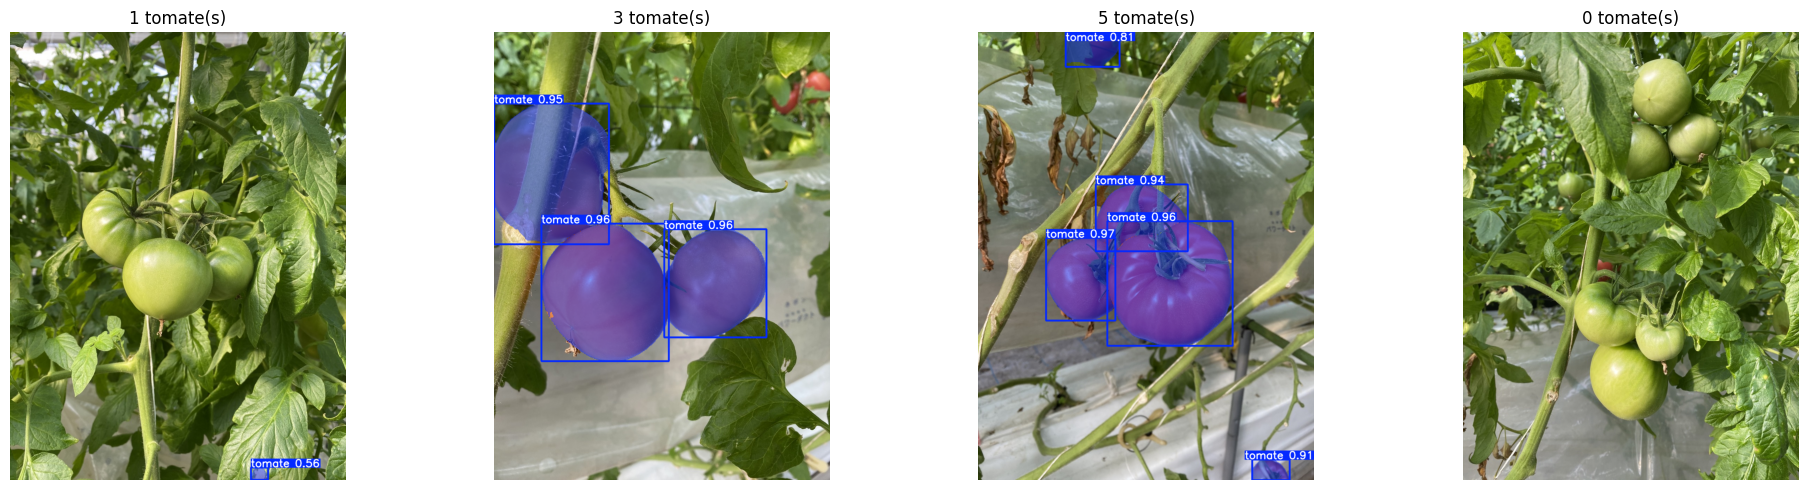

In [ ]:
import glob

imgs_test = sorted(glob.glob(os.path.join(DATA_DIR, "images", "test", "*.jpg")))[:4]
modelo = YOLO(os.path.join(WEIGHTS_DIR, "best.pt"))
fig, axes = plt.subplots(1, len(imgs_test), figsize=(5 * len(imgs_test), 5), squeeze=False)
for ax, r in zip(axes[0], modelo.predict(imgs_test, imgsz=IMGSZ, conf=0.35, verbose=False)):
    ax.imshow(r.plot()[:, :, ::-1])
    ax.set_title(f"{len(r.boxes)} tomate(s)")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# ---------------------------------------------------------------- matriz de confusión en test (umbral del sistema)
import glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

CONF_SISTEMA = 0.35   # mismo umbral de confianza que usa la página web
IOU_ACIERTO = 0.5     # IoU de máscara mínimo para que una detección cuente como acierto

if "MODELOS" not in globals():
    MODELOS = ["modelo1_yolo11s_lr0.002", "modelo2_yolo11s_lr0.0005", "modelo3_yolo11m_lr0.0005"]
    ETIQUETAS = {MODELOS[0]: "M1 · s · lr 0.002", MODELOS[1]: "M2 · s · lr 0.0005", MODELOS[2]: "M3 · m · lr 0.0005"}

def mascaras_reales(ruta_label, h, w):
    """Lee los polígonos YOLO-seg (normalizados 0-1) y devuelve una máscara bool por tomate."""
    mascaras = []
    if not os.path.isfile(ruta_label):
        return mascaras
    for linea in open(ruta_label).read().splitlines():
        v = linea.split()
        if len(v) < 7:
            continue
        pts = (np.array(v[1:], float).reshape(-1, 2) * [w, h]).round().astype(np.int32)
        m = np.zeros((h, w), np.uint8)
        cv2.fillPoly(m, [pts], 1)
        mascaras.append(m.astype(bool))
    return mascaras


def iou_mascaras(a, b):
    union = np.logical_or(a, b).sum()
    return np.logical_and(a, b).sum() / union if union else 0.0


def contar_test(nombre):
    """Cuenta TP, FP y FN en test con el umbral del sistema, emparejando por IoU de máscara."""
    modelo = YOLO(os.path.join(carpeta(nombre), "weights", "best.pt"))
    tp = fp = fn = 0
    imagenes = sorted(glob.glob(os.path.join(DATA_DIR, "images", "test", "*.jpg")))
    for ruta in imagenes:
        r = modelo.predict(ruta, imgsz=IMGSZ, conf=CONF_SISTEMA, retina_masks=True, verbose=False)[0]
        h, w = r.orig_shape
        stem = os.path.splitext(os.path.basename(ruta))[0]
        reales = mascaras_reales(os.path.join(DATA_DIR, "labels", "test", stem + ".txt"), h, w)
        preds = [] if r.masks is None else [m > 0.5 for m in r.masks.data.cpu().numpy()]
        # Emparejamiento: primero los pares con mayor IoU; cada tomate real se asigna una sola vez.
        candidatos = sorted(((iou_mascaras(p, g), i, j) for i, p in enumerate(preds) for j, g in enumerate(reales)),
                            reverse=True)
        usados_p, usados_g = set(), set()
        for iou, i, j in candidatos:
            if iou < IOU_ACIERTO:
                break
            if i not in usados_p and j not in usados_g:
                usados_p.add(i)
                usados_g.add(j)
        tp += len(usados_p)
        fp += len(preds) - len(usados_p)
        fn += len(reales) - len(usados_g)
    return {"TP": tp, "FP": fp, "FN": fn, "tomates_reales": tp + fn, "imagenes": len(imagenes)}


resultados = {m: contar_test(m) for m in MODELOS}

fig, axes = plt.subplots(1, len(MODELOS), figsize=(5 * len(MODELOS), 4.5))
for ax, m in zip(axes, MODELOS):
    c = resultados[m]
    mat = np.array([[c["TP"], c["FP"]], [c["FN"], np.nan]])
    ax.imshow(np.nan_to_num(mat), cmap="Blues", vmin=0, vmax=np.nanmax(mat))
    for (i, j), val in np.ndenumerate(mat):
        texto = "—" if np.isnan(val) else str(int(val))
        color = "white" if not np.isnan(val) and val > np.nanmax(mat) / 2 else "black"
        ax.text(j, i, texto, ha="center", va="center", fontsize=18, color=color)
    P = c["TP"] / max(1, c["TP"] + c["FP"])
    R = c["TP"] / max(1, c["TP"] + c["FN"])
    c.update(precision=round(P, 3), recall=round(R, 3), f1=round(2 * P * R / max(P + R, 1e-9), 3))
    ax.set_xticks([0, 1], ["real: tomate", "real: fondo"])
    ax.set_yticks([0, 1], ["pred: tomate", "pred: fondo"])
    ax.set_title(f"{ETIQUETAS[m]}\nP = {c['precision']:.3f} · R = {c['recall']:.3f} · F1 = {c['f1']:.3f}")
fig.suptitle(f"Matriz de confusión en test ({c['imagenes']} imágenes, {c['tomates_reales']} tomates) · "
             f"confianza ≥ {CONF_SISTEMA} · IoU de máscara ≥ {IOU_ACIERTO}")
plt.tight_layout()
plt.savefig(os.path.join(RUNS_DIR, "matriz_confusion_test.png"), dpi=150)
plt.show()

tabla_cm = pd.DataFrame(resultados).T
tabla_cm.to_csv(os.path.join(RUNS_DIR, "matriz_confusion_test.csv"))
display(tabla_cm)

## 10. Discusión (para el informe)
Preguntas guía a partir de la tabla y los gráficos:

1. **Learning rate (M1 vs M2):** ¿cuál alcanza mejor mAP50-95 de máscara? Mirá las curvas: ¿el lr más bajo converge más lento pero más estable? ¿En qué época se alcanzó el mejor valor (`mejor_epoca`)? ¿Alguno se detuvo antes por *early stopping*?
2. **Tamaño del modelo (M3 vs el mejor de M1/M2):** ¿cuánto mejora el modelo `m` en recall y mAP de máscara? Con tomates ocluidos se espera más recall, porque detecta frutos parcialmente tapados.
3. **Costo:** ¿cuántos ms por imagen agrega el modelo `m`? En el modo en vivo, cada par también pasa por SGBM y por la red, así que la latencia importa.
4. **Caja vs máscara:** la diferencia entre mAP de caja y de máscara indica qué tan bien se recorta el fruto. Para medir Z importa la máscara: una máscara que incluye hojas mezcla profundidades.
5. **Conclusión:** ¿qué modelo conviene para el sistema? Pesá la precisión contra la velocidad necesaria para el modo en vivo.